# Explaining a Fashion-MNIST CNN with LIME (PyTorch, beginner friendly)

**What you will do in this notebook**

1. Load the Fashion-MNIST dataset and explore it (basic EDA)
2. Train a small CNN in PyTorch
3. Check how good the CNN is
4. Use **LIME** to see *which parts of an image* made the CNN choose its answer

**Prerequisites:** basic PyTorch (tensors, `nn.Module`, a training loop). No explainability knowledge needed.

**How to run:** `Runtime -> Run all` (a GPU is *not* required; the CPU runtime is fine). After every code cell there is a short note explaining *what just happened* and *what output you should see*.

---

### What is LIME? (the 60-second version)

A neural network is a "black box": it gives an answer (e.g. "Sneaker, 97%") but not the reason.

**LIME** (*Local Interpretable Model-agnostic Explanations*) explains **one single prediction** at a time:

1. Cut the image into small regions called **superpixels**.
2. Create many slightly broken copies of the image by **switching random superpixels off** (painting them black).
3. Ask the CNN for its prediction on every broken copy.
4. Fit a very simple **linear model** that learns: *"when this superpixel is switched off, how much does the probability of the class change?"*
5. The linear model's weights are the explanation:
   - **positive weight** -> this region *supports* the predicted class
   - **negative weight** -> this region *argues against* it

"Model-agnostic" means LIME only needs a function `images -> probabilities`. It never looks inside the network.

## Step 0 - Install LIME

Colab already has PyTorch, torchvision, matplotlib and scikit-image. We only need to add `lime`.

In [ ]:
!pip install lime -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**What happened:** pip downloaded and installed the `lime` package.
**Expected output:** almost nothing (the `-q` flag keeps it quiet). You may see a short "Building wheel..." line. If you see a red error, re-run the cell.

## Step 1 - Imports, random seed and device

We fix the random seed so results are (mostly) repeatable, and pick the GPU if one is available.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from lime import lime_image
from skimage.segmentation import mark_boundaries

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device)

PyTorch version: 2.11.0+cpu
Using device   : cpu


**What happened:** all libraries were loaded and the device was chosen.
**Expected output:** two lines, the PyTorch version and `Using device : cpu` (or `cuda` if you switched Colab to a GPU runtime).

## Step 2 - Load Fashion-MNIST

Fashion-MNIST has 70,000 grayscale images of clothing, each **28 x 28 pixels**, in **10 classes**
(60,000 for training, 10,000 for testing).

`transforms.ToTensor()` converts each image to a tensor and scales pixel values from 0-255 down to **0.0-1.0**.

In [ ]:
transform = transforms.ToTensor()

train_ds = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_ds  = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

class_names = train_ds.classes

print("Training images:", len(train_ds))
print("Test images    :", len(test_ds))
print("Classes        :", class_names)

100%|██████████| 26.4M/26.4M [00:03<00:00, 8.42MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 139kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.53MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.3MB/s]


Training images: 60000
Test images    : 10000
Classes        : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


**What happened:** torchvision downloaded the dataset into a `./data` folder (only the first time) and wrapped it in two `Dataset` objects.
**Expected output:** some download progress bars, then

```
Training images: 60000
Test images    : 10000
Classes        : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
```

## Step 3 - Basic EDA (Exploratory Data Analysis)

Before training anything, we look at the data. Good habit: *never train on data you have not looked at.*

### 3.1 What does one sample look like?

In [ ]:
image, label = train_ds[0]

print("Type of image  :", type(image))
print("Image shape    :", tuple(image.shape), "-> (channels, height, width)")
print("Pixel min / max:", image.min().item(), "/", image.max().item())
print("Label (number) :", label)
print("Label (name)   :", class_names[label])

Type of image  : <class 'torch.Tensor'>
Image shape    : (1, 28, 28) -> (channels, height, width)
Pixel min / max: 0.0 / 1.0
Label (number) : 9
Label (name)   : Ankle boot


**What happened:** we fetched the first training sample, which is an `(image, label)` pair.
**Expected output:** the image is a `torch.Tensor` of shape `(1, 28, 28)` (1 channel because it is grayscale), pixel values lie between `0.0` and `1.0`, and the label is `9` -> `Ankle boot`.

### 3.2 Is the dataset balanced?

If one class had far more images than the others, the model could become biased towards it.

id  class         train   test
0   T-shirt/top    6000   1000
1   Trouser        6000   1000
2   Pullover       6000   1000
3   Dress          6000   1000
4   Coat           6000   1000
5   Sandal         6000   1000
6   Shirt          6000   1000
7   Sneaker        6000   1000
8   Bag            6000   1000
9   Ankle boot     6000   1000


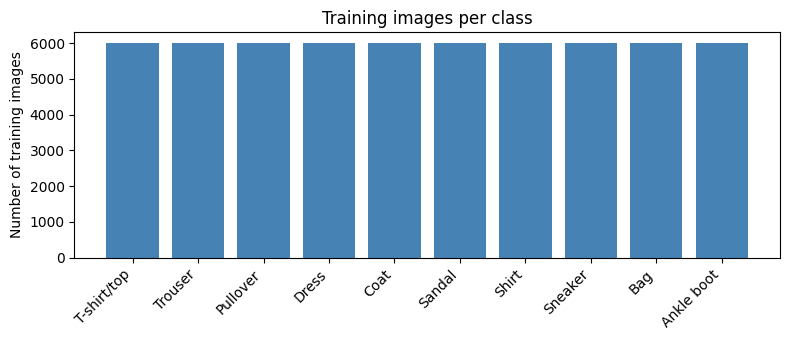

In [ ]:
train_counts = torch.bincount(train_ds.targets)
test_counts  = torch.bincount(test_ds.targets)

print(f"{'id':<3} {'class':<12} {'train':>6} {'test':>6}")
for i, name in enumerate(class_names):
    print(f"{i:<3} {name:<12} {train_counts[i].item():>6} {test_counts[i].item():>6}")

plt.figure(figsize=(8, 3.5))
plt.bar(class_names, train_counts.numpy(), color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of training images")
plt.title("Training images per class")
plt.tight_layout()
plt.show()

**What happened:** `torch.bincount` counted how many images belong to each class id.
**Expected output:** a table and a bar chart. Every class has **exactly 6,000 training** and **1,000 test** images, so the dataset is perfectly balanced and we do not need any re-weighting.

### 3.3 One example from every class

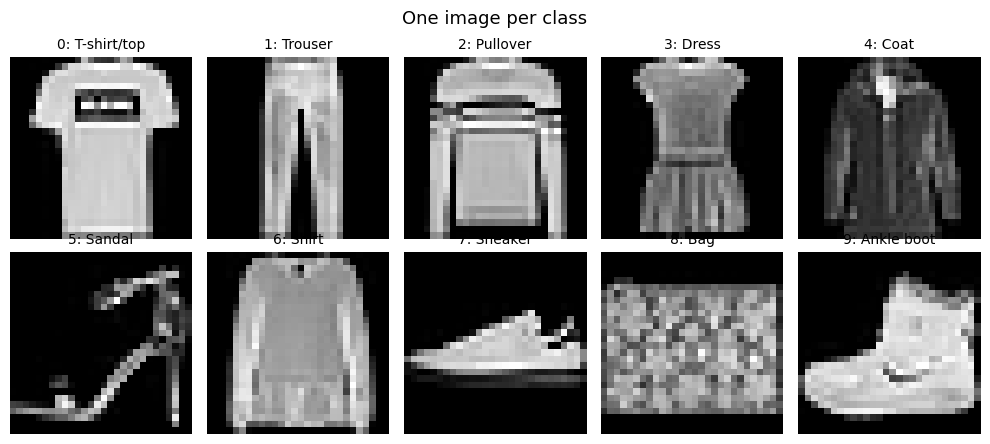

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for class_id, ax in enumerate(axes.flat):
    idx = (train_ds.targets == class_id).nonzero()[0].item()   # first image of this class
    img, _ = train_ds[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{class_id}: {class_names[class_id]}", fontsize=10)
    ax.axis("off")

plt.suptitle("One image per class", fontsize=13)
plt.tight_layout()
plt.show()

**What happened:** for each class id we found the first image with that label and displayed it with `imshow`.
**Expected output:** a 2 x 5 grid showing a T-shirt, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag and ankle boot. Notice they are small, centred, white-on-black pictures.

### 3.4 A random batch of images with labels

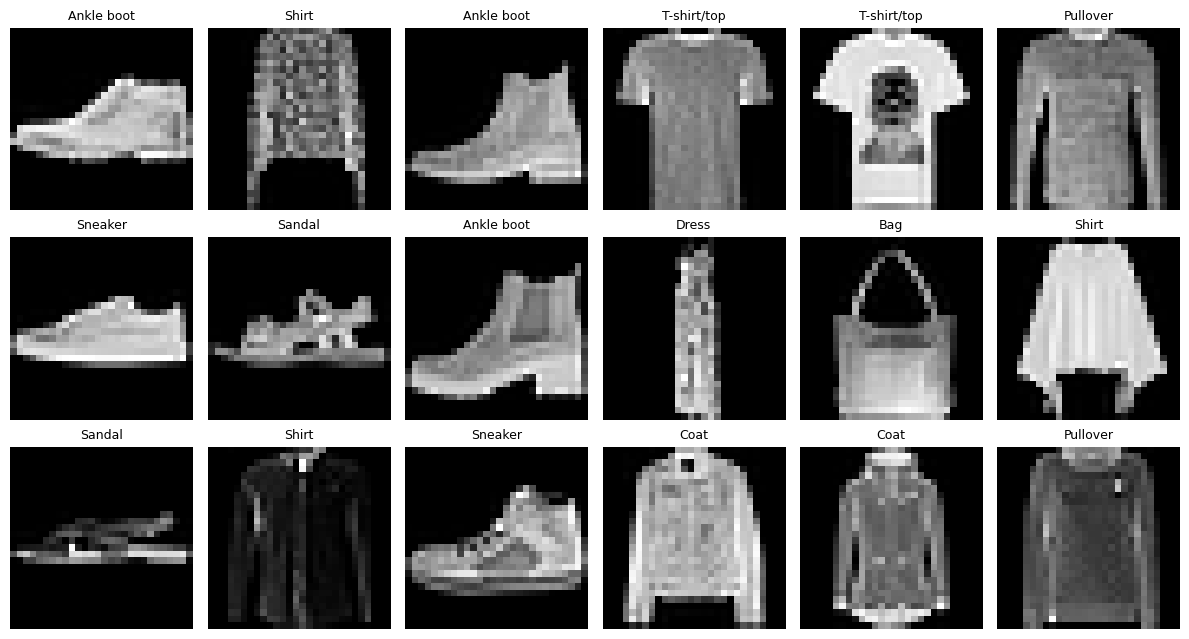

In [ ]:
rng = np.random.default_rng(SEED)
random_ids = rng.choice(len(train_ds), size=18, replace=False)

fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
for ax, i in zip(axes.flat, random_ids):
    img, lbl = train_ds[int(i)]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(class_names[lbl], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

**What happened:** we sampled 18 random training images and plotted them with their labels.
**Expected output:** a 3 x 6 grid of random clothing items. Look closely: some classes (shirt vs T-shirt vs pullover vs coat) are genuinely hard to tell apart, even for a human. Keep this in mind, it will matter when we look at mistakes later.

### 3.5 Pixel statistics

Tensor shape        : (60000, 28, 28)
Mean pixel value    : 0.2860
Std of pixel values : 0.3530
Share of pixels == 0: 50.2%


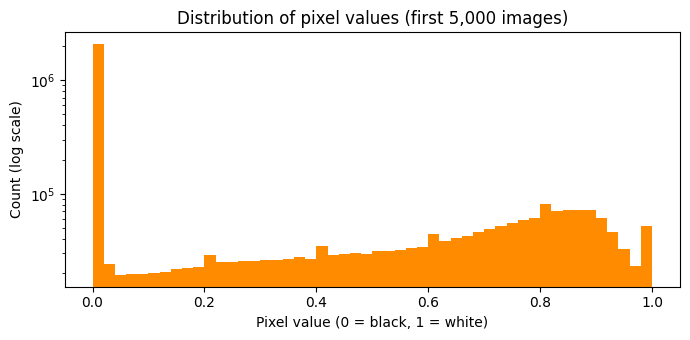

In [ ]:
all_pixels = train_ds.data.float() / 255.0      # shape (60000, 28, 28), values 0..1

print("Tensor shape        :", tuple(all_pixels.shape))
print(f"Mean pixel value    : {all_pixels.mean().item():.4f}")
print(f"Std of pixel values : {all_pixels.std().item():.4f}")
print(f"Share of pixels == 0: {(all_pixels == 0).float().mean().item() * 100:.1f}%")

plt.figure(figsize=(7, 3.5))
plt.hist(all_pixels[:5000].flatten().numpy(), bins=50, color="darkorange")
plt.yscale("log")
plt.xlabel("Pixel value (0 = black, 1 = white)")
plt.ylabel("Count (log scale)")
plt.title("Distribution of pixel values (first 5,000 images)")
plt.tight_layout()
plt.show()

**What happened:** we stacked all training images into one tensor and computed simple statistics.
**Expected output:** the mean pixel is about `0.286` and the standard deviation about `0.353`. Roughly **half of all pixels are exactly 0** (black background). The histogram has a huge spike at 0 and a smaller bump near 1.

**Why this matters for LIME:** the background is black (0). So when LIME "switches off" a region we will paint it **black**, which looks like "nothing is there", a natural choice for this dataset.

### 3.6 The "average" image of each class

Averaging all images of a class shows the typical shape the model has to learn.

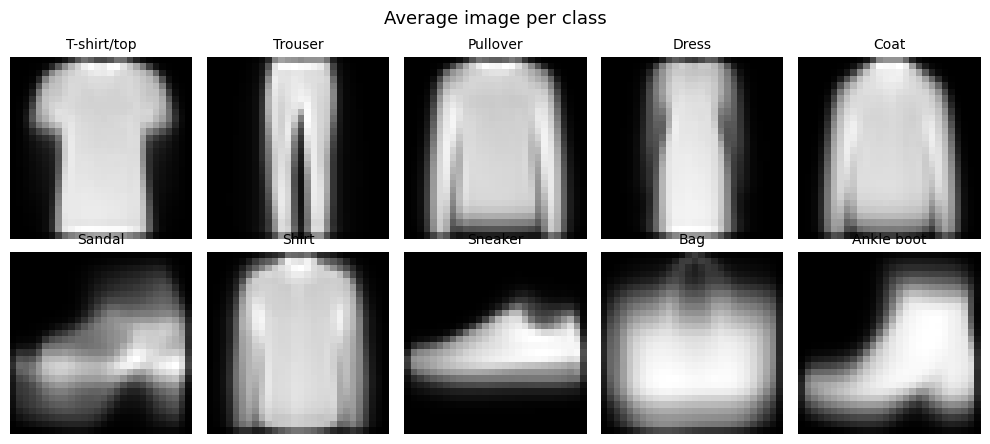

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for class_id, ax in enumerate(axes.flat):
    mean_img = all_pixels[train_ds.targets == class_id].mean(dim=0)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(class_names[class_id], fontsize=10)
    ax.axis("off")

plt.suptitle("Average image per class", fontsize=13)
plt.tight_layout()
plt.show()

**What happened:** for each class we selected all its images and took the pixel-wise mean.
**Expected output:** ten blurry "ghost" images. Trousers, sandals, sneakers and bags look very different from everything else, but **T-shirt, pullover, coat and shirt look alike**. Expect the CNN to confuse those four more often than the others.

## Step 4 - Data loaders

`DataLoader` feeds the data to the model in mini-batches. We shuffle the training data but not the test data.

In [ ]:
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))
print("Batch of images:", tuple(images.shape), "-> (batch, channels, height, width)")
print("Batch of labels:", tuple(labels.shape))
print("Batches per epoch (train):", len(train_loader))
print("Batches (test)           :", len(test_loader))

Batch of images: (128, 1, 28, 28) -> (batch, channels, height, width)
Batch of labels: (128,)
Batches per epoch (train): 469
Batches (test)           : 40


**What happened:** we created the loaders and pulled out one batch to inspect its shape.
**Expected output:**

```
Batch of images: (128, 1, 28, 28) -> (batch, channels, height, width)
Batch of labels: (128,)
Batches per epoch (train): 469
Batches (test)           : 40
```
(60,000 / 128 = 468.75, rounded up to 469 batches.)

## Step 5 - A small CNN

Two convolution blocks (conv -> ReLU -> max-pool) followed by two fully connected layers. The image size shrinks `28 -> 14 -> 7` while the number of feature maps grows `1 -> 32 -> 64`.

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (1,28,28)  -> (32,28,28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> (32,14,14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  #            -> (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> (64,7,7)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 #            -> 64*7*7 = 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),                           # 10 raw scores (logits)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SimpleCNN().to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("\nTotal trainable parameters:", f"{n_params:,}")

# quick sanity check: push one batch through the untrained network
with torch.no_grad():
    out = model(images.to(device))
print("Output shape for one batch:", tuple(out.shape), "-> (batch, 10 class scores)")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters: 421,642
Output shape for one batch: (128, 10) -> (batch, 10 class scores)


**What happened:** we defined the network, created an instance, printed its layers and ran one batch through it to be sure the shapes line up.
**Expected output:** the layer structure, `Total trainable parameters: 421,642` and `Output shape for one batch: (128, 10)`.

Note: the model outputs **logits** (raw scores). LIME needs *probabilities*, so later we will apply `softmax` ourselves.

## Step 6 - Train the CNN

Standard PyTorch loop: forward pass -> loss -> backward pass -> optimizer step. We train for 5 epochs with Adam and cross-entropy loss. We record the loss and accuracy after every epoch.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 5
history = {"loss": [], "acc": []}

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct      += (outputs.argmax(dim=1) == labels).sum().item()
        total        += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc  = correct / total * 100
    history["loss"].append(epoch_loss)
    history["acc"].append(epoch_acc)
    print(f"Epoch {epoch + 1}/{EPOCHS} | loss: {epoch_loss:.4f} | train accuracy: {epoch_acc:.2f}%")

Epoch 1/5 | loss: 0.5111 | train accuracy: 81.75%
Epoch 2/5 | loss: 0.3188 | train accuracy: 88.44%
Epoch 3/5 | loss: 0.2721 | train accuracy: 90.17%
Epoch 4/5 | loss: 0.2449 | train accuracy: 91.06%
Epoch 5/5 | loss: 0.2209 | train accuracy: 91.96%


**What happened:** the network saw the full training set 5 times and its weights were updated after every batch.
**Expected output:** five lines. The loss should **fall** every epoch (roughly from ~0.5 down to ~0.2) and training accuracy should **rise** (roughly from ~82% up to ~92-93%). Exact numbers differ a little from run to run. On the CPU runtime this takes about 1-2 minutes.

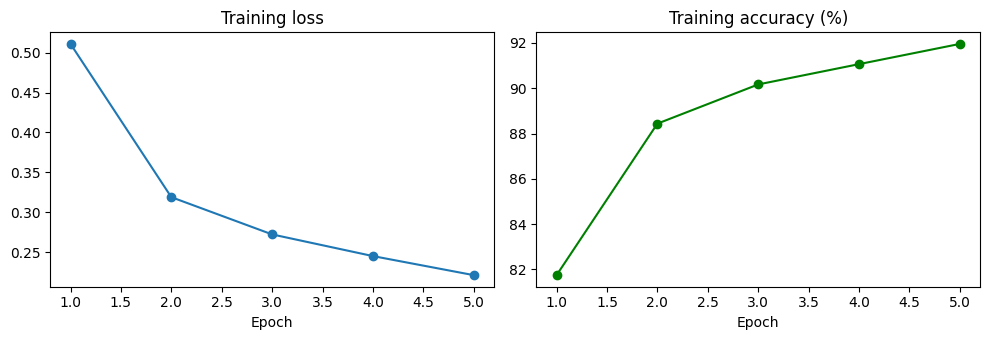

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

ax[0].plot(range(1, EPOCHS + 1), history["loss"], marker="o")
ax[0].set_title("Training loss")
ax[0].set_xlabel("Epoch")

ax[1].plot(range(1, EPOCHS + 1), history["acc"], marker="o", color="green")
ax[1].set_title("Training accuracy (%)")
ax[1].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

**What happened:** we plotted the numbers we stored in `history`.
**Expected output:** a falling loss curve and a rising accuracy curve, both flattening out towards the last epochs.

## Step 7 - Evaluate on the test set

The test images were never used for training, so this tells us how well the model generalises. We switch to `model.eval()` and turn off gradients with `torch.no_grad()`.

In [ ]:
model.eval()
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        all_preds.append(outputs.argmax(dim=1).cpu())

all_preds   = torch.cat(all_preds)        # predicted class for every test image
test_labels = test_ds.targets             # true class for every test image

test_acc = (all_preds == test_labels).float().mean().item() * 100
print(f"Overall test accuracy: {test_acc:.2f}%\n")

print("Accuracy per class:")
for i, name in enumerate(class_names):
    mask = test_labels == i
    class_acc = (all_preds[mask] == i).float().mean().item() * 100
    print(f"  {name:<12} {class_acc:5.1f}%")

Overall test accuracy: 89.89%

Accuracy per class:
  T-shirt/top   89.9%
  Trouser       97.2%
  Pullover      84.1%
  Dress         91.8%
  Coat          90.9%
  Sandal        97.6%
  Shirt         55.4%
  Sneaker       97.0%
  Bag           98.0%
  Ankle boot    97.0%


**What happened:** we predicted all 10,000 test images and compared them with the true labels, overall and per class.
**Expected output:** an overall accuracy of roughly **90%** (about 88-92% is normal). Trousers, bags, sandals, sneakers and ankle boots score very high (95%+). **Shirt is usually the worst class (often around 65-75%)**, followed by T-shirt/top, pullover and coat, exactly what the EDA "average image" predicted.

## Step 8 - Get ready for LIME

LIME needs three ingredients:

| Ingredient | What it is | Our choice |
|---|---|---|
| An image | The single image to explain | one test image |
| A **prediction function** | `images -> class probabilities` | `batch_predict` (below) |
| A **segmentation** | how to cut the image into superpixels | a simple 4 x 4-pixel grid |

### 8.1 The prediction function

LIME gives us a NumPy array of shape `(N, 28, 28, 3)` (it always works with **RGB** images, so it copies our grey channel three times). Our model wants `(N, 1, 28, 28)` PyTorch tensors. The function below translates between the two and returns **probabilities** (via `softmax`).

In [ ]:
def batch_predict(images):
    """images: numpy array (N, H, W, 3)  ->  numpy array (N, 10) of class probabilities."""
    model.eval()
    gray = images[:, :, :, 0]                                   # keep one channel -> (N, 28, 28)
    batch = torch.tensor(gray, dtype=torch.float32).unsqueeze(1)  # -> (N, 1, 28, 28)
    with torch.no_grad():
        logits = model(batch.to(device))
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()


def get_rgb_image(idx):
    """Return test image `idx` as a (28, 28, 3) float array in [0, 1], plus its true label."""
    img, lbl = test_ds[idx]
    gray = img.squeeze().numpy().astype(np.float64)             # (28, 28)
    return np.stack([gray, gray, gray], axis=-1), lbl           # (28, 28, 3)


# Test the function on one image
rgb_image, true_label = get_rgb_image(0)
probs = batch_predict(rgb_image[None])[0]                       # [None] adds the batch dimension

print("Image array shape :", rgb_image.shape)
print("True label        :", class_names[true_label])
print("Predicted         :", class_names[probs.argmax()], f"({probs.max() * 100:.1f}%)")
print("Probabilities sum to:", round(float(probs.sum()), 4))

Image array shape : (28, 28, 3)
True label        : Ankle boot
Predicted         : Ankle boot (99.8%)
Probabilities sum to: 1.0


**What happened:** we wrapped the model in a LIME-friendly function and tested it on test image #0.
**Expected output:** shape `(28, 28, 3)`, a true label (test image 0 is an *Ankle boot*), a prediction with a confidence, and probabilities that sum to `1.0`. If this cell works, LIME will work too.

### 8.2 Cutting the image into superpixels

LIME's default segmentation is designed for large colour photos and tends to find only a handful of blobs in a tiny 28 x 28 image. For small images a **regular grid** is simpler and easier to understand: we cut the image into 4 x 4-pixel squares, giving 7 x 7 = **49 superpixels**.

The function returns a 28 x 28 array where every pixel holds the *id* (0-48) of the square it belongs to.

Segment map shape      : (28, 28)
Number of superpixels  : 49
Segment ids in top-left 8x8 pixels:
 [[0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [7 7 7 7 8 8 8 8]
 [7 7 7 7 8 8 8 8]
 [7 7 7 7 8 8 8 8]
 [7 7 7 7 8 8 8 8]]


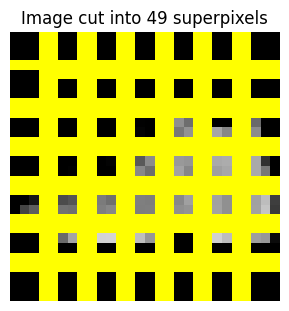

In [ ]:
BLOCK = 4   # size of each square in pixels (try 2, 7 or 14 later!)

def grid_segmentation(image):
    h, w = image.shape[:2]
    blocks_per_row = w // BLOCK
    rows = np.arange(h) // BLOCK
    cols = np.arange(w) // BLOCK
    return (rows[:, None] * blocks_per_row + cols[None, :]).astype(int)


segments = grid_segmentation(rgb_image)
print("Segment map shape      :", segments.shape)
print("Number of superpixels  :", len(np.unique(segments)))
print("Segment ids in top-left 8x8 pixels:\n", segments[:8, :8])

plt.figure(figsize=(3.5, 3.5))
plt.imshow(mark_boundaries(rgb_image, segments, color=(1, 1, 0)))
plt.title("Image cut into 49 superpixels")
plt.axis("off")
plt.show()

**What happened:** we built the superpixel map and drew its borders (yellow) on the image.
**Expected output:** `Number of superpixels: 49`, a small printed matrix of ids (the top-left 8 x 8 pixels belong to ids `0, 1, 7, 8`), and the test image overlaid with a yellow 7 x 7 grid.

### 8.3 Peek inside LIME: what are "perturbed" images?

This is LIME's core trick, done by hand for 5 random copies. For each copy we randomly decide which of the 49 squares stay **on** (original pixels) and which go **off** (black), then ask the CNN what it thinks. LIME does exactly this ~1,000 times and then looks for a pattern.

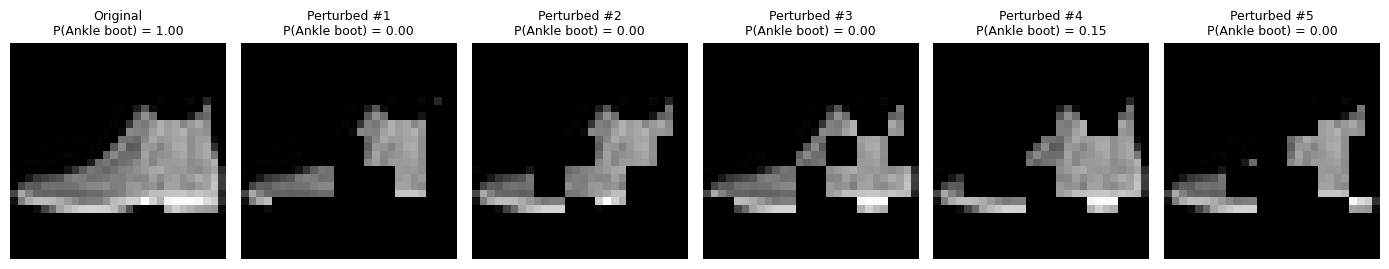

In [ ]:
rng = np.random.default_rng(0)
n_segments = len(np.unique(segments))
target_class = int(probs.argmax())

fig, axes = plt.subplots(1, 6, figsize=(14, 3))

axes[0].imshow(rgb_image)
axes[0].set_title(f"Original\nP({class_names[target_class]}) = {probs[target_class]:.2f}", fontsize=9)
axes[0].axis("off")

for k in range(1, 6):
    keep = rng.integers(0, 2, size=n_segments)       # 1 = keep this square, 0 = switch it off
    keep_map = keep[segments]                         # expand to a (28, 28) pixel mask
    perturbed = rgb_image * keep_map[:, :, None]      # black out the switched-off squares
    p = batch_predict(perturbed[None])[0][target_class]
    axes[k].imshow(perturbed)
    axes[k].set_title(f"Perturbed #{k}\nP({class_names[target_class]}) = {p:.2f}", fontsize=9)
    axes[k].axis("off")

plt.tight_layout()
plt.show()

**What happened:** we generated five randomly "damaged" versions of the image and checked how the predicted probability of the original class changed.
**Expected output:** one original and five images with random black squares. The probability usually **drops** when important squares are removed and stays high when only unimportant (e.g. background) squares are removed. LIME's job is to turn this pattern into per-square importance scores.

## Step 9 - Run LIME on one image

Key arguments of `explain_instance`:

| Argument | Meaning |
|---|---|
| `image` | the `(28, 28, 3)` array to explain |
| `classifier_fn` | our `batch_predict` |
| `top_labels=3` | explain the 3 most likely classes |
| `hide_color=0` | switched-off superpixels become **black** (matches the dataset's background) |
| `num_samples=1000` | how many perturbed images to create (more = more stable, slower) |
| `segmentation_fn` | our grid segmentation |

In [ ]:
explainer = lime_image.LimeImageExplainer(random_state=SEED)

explanation = explainer.explain_instance(
    image=rgb_image,
    classifier_fn=batch_predict,
    top_labels=3,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=grid_segmentation,
    batch_size=100,
    random_seed=SEED,
)

print("Top-3 classes LIME explained:")
for lbl in explanation.top_labels:
    print(f"  {class_names[lbl]:<12} model probability = {probs[lbl]:.3f}")

**What happened:** LIME created 1,000 perturbed images, got the CNN's probabilities for all of them, and fitted a weighted linear model for each of the top 3 classes. A progress bar shows the CNN being called on the perturbed images.
**Expected output:** a progress bar reaching `1000/1000` (a few seconds) followed by the three most likely classes with their probabilities (the first one should be the model's top prediction from Step 8.1).

## Step 10 - Look at the explanation

We show three things for the predicted class:

1. the original image
2. the **top 5 positive superpixels** (the regions that most *support* the prediction), outlined in yellow
3. a **heat-map** of all 49 weights: **red = supports** the class, **blue = argues against** it

In [ ]:
def lime_heatmap(explanation, label):
    """Turn LIME's (segment_id, weight) pairs into a 28x28 heat-map."""
    heat = np.zeros(explanation.segments.shape)
    for seg_id, weight in explanation.local_exp[label]:
        heat[explanation.segments == seg_id] = weight
    return heat


label = explanation.top_labels[0]                      # the model's top prediction
heat  = lime_heatmap(explanation, label)

# the 5 most supportive superpixels
_, mask = explanation.get_image_and_mask(label, positive_only=True, num_features=5, hide_rest=False)

limit = np.abs(heat).max()                             # symmetric colour scale around 0

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))

axes[0].imshow(rgb_image)
axes[0].set_title(f"Original\ntrue: {class_names[true_label]}")

axes[1].imshow(mark_boundaries(rgb_image, mask, color=(1, 1, 0)))
axes[1].set_title(f"Top 5 supporting regions\nfor '{class_names[label]}'")

im = axes[2].imshow(heat, cmap="seismic", vmin=-limit, vmax=limit)
axes[2].set_title("LIME weights\n(red = for, blue = against)")
plt.colorbar(im, ax=axes[2], fraction=0.046)

for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

**What happened:** we read LIME's linear-model weights (`explanation.local_exp`) and painted each superpixel with its weight.
**Expected output:** three panels. For the ankle boot, the strongest red squares should sit **on the boot itself** (its shape, shaft and sole) rather than on the black background. Blue squares are regions that, if kept, would have *lowered* the "Ankle boot" probability, often parts that make the object look like a sneaker or sandal. Colours depend slightly on your trained model.

### 10.1 Sanity check: do the highlighted regions really matter?

An explanation is only useful if it is *true*. Test: black out the **3 most important** squares and see whether the model's confidence in that class really drops.

In [ ]:
_, top_mask = explanation.get_image_and_mask(label, positive_only=True, num_features=3, hide_rest=False)

damaged = rgb_image.copy()
damaged[top_mask == 1] = 0                               # switch the 3 top squares off

p_before = batch_predict(rgb_image[None])[0]
p_after  = batch_predict(damaged[None])[0]

print(f"P({class_names[label]}) before: {p_before[label]:.3f}")
print(f"P({class_names[label]}) after : {p_after[label]:.3f}")
print("Prediction after damage:", class_names[p_after.argmax()], f"({p_after.max() * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(rgb_image); axes[0].set_title("Before")
axes[1].imshow(damaged);   axes[1].set_title("3 key squares removed")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

**What happened:** we removed only the three squares LIME called most supportive and re-asked the model.
**Expected output:** the probability of the class should go **down**, often noticeably, and for some images the predicted class even changes. That is evidence the explanation reflects what the model actually uses. (If the model is extremely confident and the object is large, a few squares may not be enough to change much; try `num_features=6` or `8`.)

## Step 11 - Explain one image from several classes

Let's explain six different kinds of clothing to see whether the model looks at sensible regions. We pick the first test image of each chosen class.

In [ ]:
chosen_classes = [0, 2, 5, 6, 7, 9]    # T-shirt, Pullover, Sandal, Shirt, Sneaker, Ankle boot
chosen_ids = [(test_ds.targets == c).nonzero()[0].item() for c in chosen_classes]

fig, axes = plt.subplots(2, len(chosen_ids), figsize=(2.4 * len(chosen_ids), 5.2))

for col, idx in enumerate(chosen_ids):
    rgb, true_lbl = get_rgb_image(idx)

    expl = explainer.explain_instance(
        rgb, batch_predict, top_labels=1, hide_color=0, num_samples=1000,
        segmentation_fn=grid_segmentation, batch_size=100,
        random_seed=SEED,
    )
    pred_lbl = expl.top_labels[0]
    conf = batch_predict(rgb[None])[0][pred_lbl]
    h = lime_heatmap(expl, pred_lbl)
    lim = np.abs(h).max()

    axes[0, col].imshow(rgb)
    axes[0, col].set_title(f"true: {class_names[true_lbl]}\npred: {class_names[pred_lbl]} ({conf:.2f})", fontsize=9)
    axes[1, col].imshow(h, cmap="seismic", vmin=-lim, vmax=lim)
    axes[1, col].set_title("LIME weights", fontsize=9)
    axes[0, col].axis("off"); axes[1, col].axis("off")

plt.tight_layout()
plt.show()

**What happened:** the same explain-then-plot recipe was applied to six images (about 10-30 seconds in total). You will see one progress bar per image; that is normal.
**Expected output:** top row = images with true and predicted class, bottom row = LIME heat-maps. In most cases the **red regions lie on the clothing item** and follow its characteristic parts (sleeves for the pullover and shirt, the sole for the sneaker and sandal, the shaft for the boot). That is what we hope to see: the model looks at the object, not at random background.

## Step 12 - Explaining a mistake

LIME is most useful when the model is **wrong**. We take the first misclassified test image and explain *both* the class the model chose and the class that was actually correct. We ask LIME for all 10 classes (`top_labels=10`) so both are available.

In [ ]:
wrong_ids = (all_preds != test_labels).nonzero().flatten()
print("Number of misclassified test images:", len(wrong_ids))

idx = wrong_ids[0].item()
rgb, true_lbl = get_rgb_image(idx)
probs_w = batch_predict(rgb[None])[0]
pred_lbl = int(probs_w.argmax())

print(f"Test image #{idx}: true = {class_names[true_lbl]} ({probs_w[true_lbl]:.2f}), "
      f"predicted = {class_names[pred_lbl]} ({probs_w[pred_lbl]:.2f})")

expl = explainer.explain_instance(
    rgb, batch_predict, top_labels=10, hide_color=0, num_samples=1000,
    segmentation_fn=grid_segmentation, batch_size=100,
    random_seed=SEED,
)

h_pred = lime_heatmap(expl, pred_lbl)
h_true = lime_heatmap(expl, true_lbl)
lim = max(np.abs(h_pred).max(), np.abs(h_true).max())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(rgb)
axes[0].set_title(f"Image #{idx}\ntrue: {class_names[true_lbl]}")
axes[1].imshow(h_pred, cmap="seismic", vmin=-lim, vmax=lim)
axes[1].set_title(f"Why '{class_names[pred_lbl]}'?\n(model's wrong answer)")
im = axes[2].imshow(h_true, cmap="seismic", vmin=-lim, vmax=lim)
axes[2].set_title(f"Why '{class_names[true_lbl]}'?\n(the correct answer)")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

**What happened:** we found all test images where `prediction != label`, took the first one, and compared LIME's explanation for the wrong class with the explanation for the right class (same colour scale for a fair comparison).
**Expected output:** roughly 900-1,100 misclassified images (about 10% of 10,000), then one example, typically a shirt / T-shirt / pullover / coat mix-up. Look for **where the red is**: perhaps the wrong class is supported by a region such as the collar or sleeve shape that looks similar in both classes. This is how LIME helps you debug a model.

## Wrap-up

**What you did**

- Explored Fashion-MNIST: balanced classes, black background, similar-looking clothing classes
- Trained a small CNN (about 90% test accuracy)
- Wrote a `batch_predict` function (`images -> probabilities`), the only thing LIME needs from your model
- Used LIME to see which superpixels support or oppose a prediction, validated an explanation by removing regions, and examined a mistake

**Things to keep in mind**

- LIME explains **one prediction at a time** (it is *local*). It does not describe the whole model.
- It is **random**: different seeds or fewer `num_samples` give slightly different explanations. Fix the seed and use more samples when you need stability.
- The explanation depends on the **segmentation** and on `hide_color`. Different choices can give different pictures.
- It shows what the model *uses*, which is not always what a human would find sensible. That is the point: it exposes shortcuts.

**Experiments to try**

1. Change `BLOCK` to `2` (more, smaller superpixels) or `7` (fewer, larger ones) and re-run Steps 8-10.
2. Change `num_samples` to `100` vs `5000` and see how stable the heat-map is.
3. Change `hide_color=0` to `hide_color=1` (white). Do explanations change?
4. Train for 1 epoch only instead of 5. Do the explanations look less sensible?
5. Explain several misclassified images, are the same regions responsible every time?

**Further reading:** Ribeiro et al., *"Why Should I Trust You?": Explaining the Predictions of Any Classifier* (2016), and the `lime` GitHub repository (`marcotcr/lime`).